# Train — ResNet-50

Trains and evaluates ResNet-50 with the tuned hyperparameters in `ARCH_HYPERPARAMS["resnet50"]`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: chronological
Train-time augmentation: off
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']


## Data loaders and class weights

In [2]:
cfg = ARCH_HYPERPARAMS["resnet50"]

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-50: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-50: micro batch = 16, accumulation steps = 6 (effective batch size ≈ 96, target = 96)
Train: 947 | Val: 229 | Test: 567


## Model

In [3]:
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ResNet-50] Gradient accumulation: 6 micro-batches per optimizer step.


[ResNet-50] Epoch   1/100 | LR: 1.95e-04 | train loss 1.0088 acc 0.574 | val loss 0.7739 acc 0.716 *


[ResNet-50] Epoch   2/100 | LR: 1.95e-04 | train loss 0.7415 acc 0.734 | val loss 0.7187 acc 0.664 *


[ResNet-50] Epoch   3/100 | LR: 1.95e-04 | train loss 0.5223 acc 0.807 | val loss 0.5904 acc 0.747 *


[ResNet-50] Epoch   4/100 | LR: 1.95e-04 | train loss 0.3521 acc 0.871 | val loss 0.8772 acc 0.712


...

[ResNet-50] Epoch   9/100 | LR: 1.95e-04 | train loss 0.1329 acc 0.957 | val loss 0.8471 acc 0.773


[ResNet-50] Epoch  10/100 | LR: 1.95e-04 | train loss 0.1080 acc 0.968 | val loss 1.0241 acc 0.707


[ResNet-50] Epoch  11/100 | LR: 1.95e-04 | train loss 0.1110 acc 0.969 | val loss 0.8128 acc 0.786


[ResNet-50] Epoch  12/100 | LR: 1.95e-04 | train loss 0.0717 acc 0.984 | val loss 0.7589 acc 0.764


[ResNet-50] Epoch  13/100 | LR: 1.95e-04 | train loss 0.0578 acc 0.984 | val loss 0.8468 acc 0.777

[ResNet-50] No val loss improvement for 10 epochs, stopping at epoch 13.

[ResNet-50] Restored best checkpoint (val loss = 0.5904)


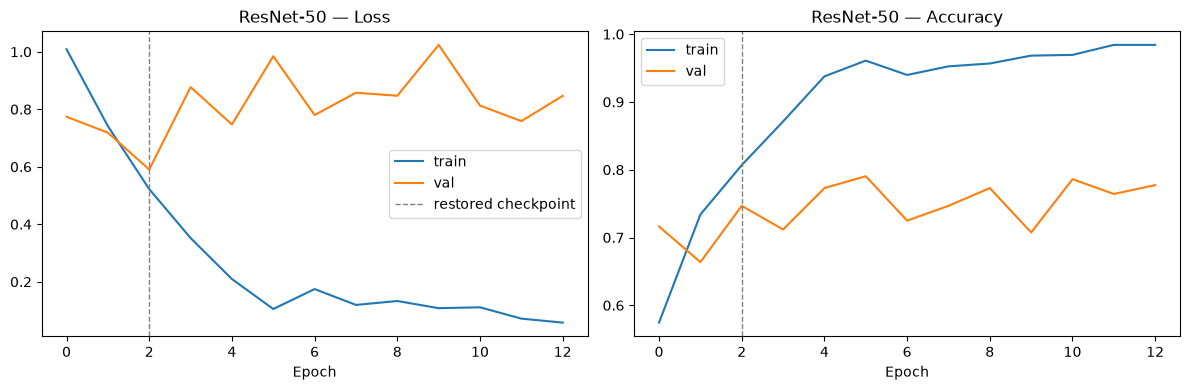

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-50", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-50")

## Evaluate on the test set

[ResNet-50] Test accuracy: 0.737


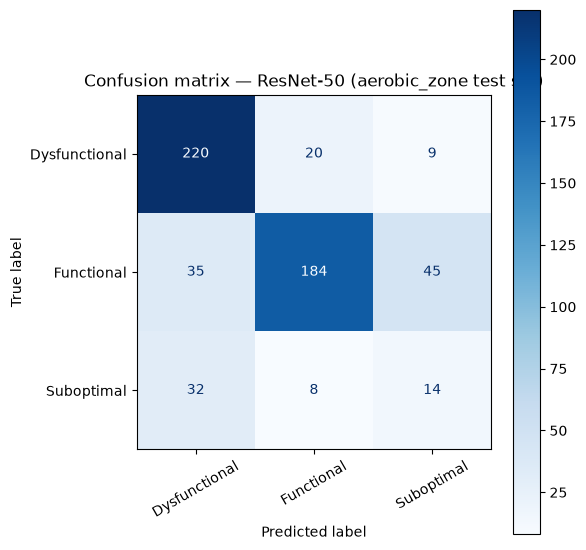

               precision    recall  f1-score   support

Dysfunctional      0.767     0.884     0.821       249
   Functional      0.868     0.697     0.773       264
   Suboptimal      0.206     0.259     0.230        54

     accuracy                          0.737       567
    macro avg      0.613     0.613     0.608       567
 weighted avg      0.760     0.737     0.742       567



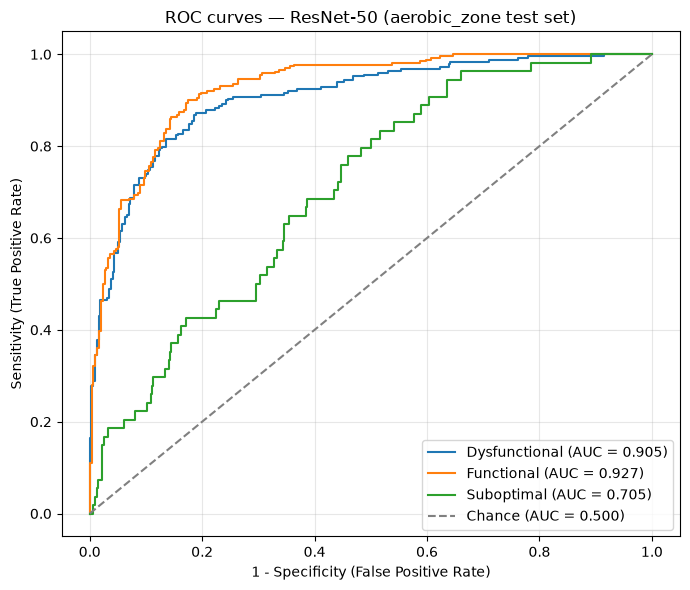

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.905
  Functional     : 0.927
  Suboptimal     : 0.705

Mean AUC (over 3/3 classes with test examples): 0.845


(np.float64(0.7372134038800705),
 {'Dysfunctional': 0.9048394837210477,
  'Functional': 0.9270302030203021,
  'Suboptimal': 0.7046061656198108})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-50", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ResNet-50", "resnet50")

Saved results to ../results/aerobic_zone_noaug/results_aerobic_zone_resnet50_chronological.pkl
Saved model weights to ../models/pad/aerobic_zone_noaug/aerobic_zone_resnet50_chronological.pt
